# Sales & Demand Planning
**Student notebook**

## Sales-planning case
A sales record tells us what was sold. A forecast estimates future sales. A demand plan combines that estimate with clearly stated business assumptions.

We follow two product codes, SKU_A and SKU_B, and prepare a simple sales estimate for the week labelled **29 December 2024**. Tasks 2, 4 and 5 focus on SKU_A; the history and forecast comparison also include SKU_B.

Run setup and Baseline first, then Tasks 1–5. Each task uses its own stated reference. The promotion assumption is not applied in Task 4. Task 5 compares the original reference with the assumed 20% adjustment.

For each experiment, first notice a specific output, then think about its meaning, and explain it in one or two sentences to a sales-planning colleague. Use the displayed values; no extra calculation is needed.


## Terms used in this notebook
**SKU** is a product code. **Units/week** is the number sold or estimated for one week. A **sales target** is an ambition; a **forecast** is an estimate, not a promise.

A **moving average** averages the preceding weeks. MA3 uses three prior calendar weeks and MA6 uses six. The **naïve forecast** uses the previous week's sales. **Forecast error** is forecast minus actual. **Absolute error** ignores the sign. **MAE** (mean absolute error) averages the absolute errors across the weeks evaluated. Positive **bias** means overforecasting on average.

A **planning horizon** is how far into the future a plan looks. Always read a quantity together with its time period.


## Dataset
One row represents one product in a Sunday-labelled calendar week. Sales_Units is recorded units sold. Is_Promo is 1 for a promotion, 0 for no promotion, or unknown. Price has no supplied currency, so we do not calculate revenue. The source has 104 weeks per product. Company provenance is not established.

The provided preparation keeps the original file, removes three exact repeated exports under a teaching assumption, and holds aside (quarantines) an invalid date and both conflicting records for review. Negative values remain unresolved. Missing sales stay missing and promotion peaks remain unchanged. You read these checks; you do not have to design a cleaning method.

The next-week promotion adjustment and the actual-sales outcomes 150/190 are teaching assumptions, not observations in the source CSV. Task 4 assumes a constant weekly level across the chosen horizon. The embedded raw snapshot matches the supplied CSV and allows execution without an external download.


## How we check the forecast
The code uses earlier weeks to predict each later week. It never uses a week's own sales in its prediction. Missing actuals are not scored as zero.

We compare methods on 12 validation weeks, 11 August–27 October 2024, using the same eligible dates per product. Validation means the period used to compare methods. The code chooses A's method by validation MAE, then checks it on 8 separate final weeks, 3 November–22 December 2024. We do not select again on that final period. The helper handles the separation; read the errors and the number of weeks evaluated.

A previous observed actual may inform a later weekly prediction. Sparse coverage for B limits what we can conclude.


## Provided setup
Run these folded helper cells in order. Only edit the marked task settings. The helpers do the arithmetic so you can focus on what changes and why.

In [1]:
import io
import base64
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


RAW_SHA256 = 'e044f37853df000d9760dac449ed94edc219bfd8b0ac7ba60344d9038b377c57'
RAW_SNAPSHOT = 'V2VlayxTS1UsU2FsZXNfVW5pdHMsSXNfUHJvbW8sUHJpY2UKMjAyMy0wNS0xNCxTS1VfQiwyMTMsMCwxOS40OQoyMDIzLTAzLTE5LFNLVV9BLDE1NywwLDE0Ljk5CjIwMjQtMDktMjksU0tVX0IsLTI1LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMDEtMjEsU0tVX0IsMTk3LDAsMTkuNDkKMjAyMy0xMS0xOSxTS1VfQiwxODcsMCwxOS40OQoyMDI0LTA1LTI2LFNLVV9BLDE4MiwwLDE0Ljk5CjIwMjQtMTEtMTAsU0tVX0EsMTQ3LDAsMTQuOTkKMjAyMy0wNS0xNCxTS1VfQSwxNDUsMCwxNC45OQoyMDIzLTAxLTI5LFNLVV9BLDE0OCwwLDE0Ljk5CjIwMjMtMDItMTIsU0tVX0EsMTcwLDAsMTQuOTkKMjAyNC0xMS0yNCxTS1VfQSwxNDYsMCwxNC45OQoyMDI0LTAyLTA0LFNLVV9BLDIyNSwxLDkuOTkKMjAyMy0wNy0zMCxTS1VfQSwxMzEsMCwxNC45OQoyMDI0LTAxLTE0LFNLVV9CLDE5NiwwLDE5LjQ5CjIwMjMtMDUtMjEsU0tVX0IsMjI3LDAsMTkuNDkKMjAyMy0xMC0wMSxTS1VfQSwxMzAsMCwxNC45OQoyMDI0LTA5LTE1LFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMTItMDEsU0tVX0EsMTM3LDAsMTQuOTkKMjAyNC0wMy0xMCxTS1VfQiwyMzAsMCwxOS40OQoyMDIzLTA0LTAyLFNLVV9BLDE0MywwLDE0Ljk5CjIwMjMtMDMtMjYsU0tVX0EsMTY1LDAsMTQuOTkKMjAyNC0xMC0yNyxTS1VfQSwxMjcsMCwxNC45OQoyMDIzLTAyLTEyLFNLVV9CLDE3OSwwLDE5LjQ5CjIwMjQtMDItMTgsU0tVX0IsMjEzLDAsMTkuNDkKMjAyNC0wNy0xNCxTS1VfQiwyMTYsMCwxOS40OQoyMDIzLTA5LTAzLFNLVV9CLDE4MywwLDE5LjQ5CjIwMjQtMDgtMjUsU0tVX0EsMTUwLDAsMTQuOTkKMjAyNC0wMy0xNyxTS1VfQSwxNjAsMCwxNC45OQoyMDIzLTAzLTA1LFNLVV9CLDIyMiwwLDE5LjQ5CjIwMjQtMDMtMjQsU0tVX0IsMzE2LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMDEtMTQsU0tVX0EsLTUsMCwxNC45OQoyMDI0LTA4LTE4LFNLVV9BLDEzNywwLDE0Ljk5CjIwMjMtMDYtMTgsU0tVX0IsMjA3LDAsMTkuNDkKMjAyMy0wNC0yMyxTS1VfQiwtNSwwLDE5LjQ5CjIwMjMtMDUtMDcsU0tVX0EsMTUxLDAsMTQuOTkKMjAyMy0wNC0wMixTS1VfQSwxNDMsMCwxNC45OQoyMDIzLTAxLTAxLFNLVV9BLDE0NSwwLDE0Ljk5CjIwMjMtMDQtMTYsU0tVX0IsMjk3LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjMtMDEtMTUsU0tVX0IsMjcyLDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjMtMDQtMDIsU0tVX0IsMjA2LDAsMTkuNDkKMjAyNC0wMS0xNCxTS1VfQSwxNjYsMCwxNC45OQoyMDIzLTAxLTE1LFNLVV9BLDIxMCwxLDkuOTkKMjAyMy0wMS0wOCxTS1VfQiwxOTYsMCwxOS40OQoyMDI0LTAxLTA3LFNLVV9BLDE1OSwwLDE0Ljk5CjIwMjQtMDQtMDcsU0tVX0EsMTcyLDAsMTQuOTkKMjAyMy0wNC0yMyxTS1VfQSwxNTIsMCwxNC45OQoyMDI0LTA5LTI5LFNLVV9BLDIwMywxLDkuOTkKMjAyNC0xMS0xNyxTS1VfQSwyMDUsMSw5Ljk5CjIwMjMtMTItMTcsU0tVX0EsMjA3LDEsOS45OQoyMDI0LTA1LTI2LFNLVV9CLDIyNSwwLDE5LjQ5CjIwMjMtMTAtMDgsU0tVX0IsMTc5LDAsMTkuNDkKMjAyNC0wMS0yMSxTS1VfQSwxNjcsMCwxNC45OQoyMDI0LTAzLTAzLFNLVV9BLDE2OCwwLDE0Ljk5CjIwMjQtMDktMDEsU0tVX0IsMTkzLDAsMTkuNDkKMjAyMy0wOS0xMCxTS1VfQSwxODIsMSw5Ljk5CjIwMjMtMDctMjMsU0tVX0IsMjM5LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMTItMDEsU0tVX0EsMTM3LDAsMTQuOTkKMjAyNC0wOS0wOCxTS1VfQiwyMTAsMCwxOS40OQoyMDIzLTA0LTA5LFNLVV9CLDIxNiwwLDE5LjQ5CjIwMjMtMDItMDUsU0tVX0EsMTUwLDAsMTQuOTkKMjAyNC0wNC0wNyxTS1VfQiwyNDYsMCwxOS40OQoyMDI0LTA2LTA5LFNLVV9CLDE5OSwwLDE5LjQ5CjIwMjQtMTAtMDYsU0tVX0EsMTMyLDAsMTQuOTkKMjAyNC0xMC0yMCxTS1VfQiwxNzcsMCwxOS40OQoyMDIzLTEyLTMxLFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMDYtMDIsU0tVX0EsMTM4LDAsMTQuOTkKMjAyMy0wNy0wOSxTS1VfQSwxNDcsMCwxNC45OQoyMDIzLTExLTI2LFNLVV9CLDE4OSwwLDE5LjQ5CjIwMjMtMDMtMTIsU0tVX0IsMjA5LDAsMTkuNDkKMjAyMy0wOS0yNCxTS1VfQSwxMTQsMCwxNC45OQoyMDI0LTA4LTA0LFNLVV9BLDE0MCwwLDE0Ljk5CjIwMjMtMTItMTAsU0tVX0EsMTI1LDAsMTQuOTkKMjAyMy0wOS0yNCxTS1VfQiwxNzgsMCwxOS40OQoyMDIzLTA2LTExLFNLVV9BLDEzNywwLDE0Ljk5CjIwMjQtMTAtMjAsU0tVX0EsMTM2LDAsMTQuOTkKMjAyMy0wOC0xMyxTS1VfQSwxMzMsMCwxNC45OQoyMDI0LTAzLTMxLFNLVV9CLDIwNCwwLDE5LjQ5CjIwMjQtMDktMjIsU0tVX0EsMTM5LDAsMTQuOTkKMjAyMy0xMS0xOSxTS1VfQSwxMzEsMCwxNC45OQoyMDI0LTExLTAzLFNLVV9BLDE0NiwwLDE0Ljk5CjIwMjQtMDYtMDIsU0tVX0IsMjI3LDAsMTkuNDkKMjAyMy0xMC0wOCxTS1VfQSwxMzYsMCwxNC45OQoyMDIzLTA3LTAyLFNLVV9CLDE5MCwwLDE5LjQ5CjIwMjMtMDgtMTMsU0tVX0IsMTc1LDAsMTkuNDkKMjAyNC0xMi0wOCxTS1VfQSwxNDksMCwxNC45OQoyMDIzLTAyLTE5LFNLVV9BLDE2NCwwLDE0Ljk5CjIwMjMtMDQtMzAsU0tVX0EsMTY0LDAsMTQuOTkKMjAyNC0xMS0xNyxTS1VfQiwxODgsMCwxOS40OQoyMDIzLTExLTEyLFNLVV9BLDEyNywwLDE0Ljk5CjIwMjMtMDgtMjcsU0tVX0IsMTk5LDAsMTkuNDkKMjAyNC0wOC0wNCxTS1VfQiwxOTMsMCwxOS40OQoyMDIzLTAyLTA1LFNLVV9CLDIxMywwLDE5LjQ5CjIwMjMtMTEtMjYsU0tVX0EsMTQ5LDAsMTQuOTkKMjAyNC0wMS0yOCxTS1VfQSwxNTIsMCwxNC45OQoyMDIzLTA1LTA3LFNLVV9CLDIwNiwwLDE5LjQ5CjIwMjQtMTItMTUsU0tVX0EsMTUyLDAsMTQuOTkKMjAyNC0xMC0xMyxTS1VfQSwxMzYsMCwxNC45OQoyMDIzLTA5LTAzLFNLVV9BLDExNywwLDE0Ljk5CjIwMjQtMDUtMTIsU0tVX0EsMjUyLDEsOS45OQoyMDI0LTAzLTE3LFNLVV9CLDIzMiwwLDE5LjQ5CjIwMjQtMDQtMTQsU0tVX0IsMjI0LDAsMTkuNDkKMjAyMy0xMC0yMixTS1VfQiwxNzgsMCwxOS40OQoyMDI0LTA2LTE2LFNLVV9CLDIxOCwwLDE5LjQ5CjIwMjMtMDEtMDEsU0tVX0IsMTg5LDAsMTkuNDkKMjAyMy0wNS0yMSxTS1VfQSwxNzIsMCwxNC45OQoyMDI0LTAyLTI1LFNLVV9BLDE2NCwwLDE0Ljk5CjIwMjQtMDYtMTYsU0tVX0EsMTYxLDAsMTQuOTkKMjAyNC0wOS0xNSxTS1VfQiwyMDQsMCwxOS40OQoyMDI0LTAzLTEwLFNLVV9BLDE2MCwwLDE0Ljk5CjIwMjMtMTEtMDUsU0tVX0IsMTkyLDAsMTkuNDkKMjAyNC0wNS0wNSxTS1VfQiwyMjAsMCwxOS40OQoyMDIzLTEwLTE1LFNLVV9CLDE4NCwwLDE5LjQ5CjIwMjMtMTAtMDEsU0tVX0IsMTgyLDAsMTkuNDkKMjAyMy0wMS0yMixTS1VfQSwxNjMsMCwxNC45OQoyMDIzLTA2LTA0LFNLVV9BLDE1NCwwLDE0Ljk5CjIwMjMtMDQtMDksU0tVX0EsMTQ1LDAsMTQuOTkKMjAyMy0wMy0xOSxTS1VfQiwyMDUsMCwxOS40OQoyMDIzLTA3LTIzLFNLVV9BLDEzNiwwLDE0Ljk5CjIwMjMtMTItMzEsU0tVX0IsMTgyLDAsMTkuNDkKMjAyNC0xMi0xNSxTS1VfQiwyMTAsMCwxOS40OQoyMDI0LTA2LTMwLFNLVV9BLDE1NywwLDE0Ljk5CjIwMjMtMDUtMjgsU0tVX0EsMjE2LDEsOS45OQoyMDI0LTExLTI0LFNLVV9CLDI2OCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTA1LTE5LFNLVV9CLDMwMywxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDIzLTEyLTEwLFNLVV9CLDI2OCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTAxLTI4LFNLVV9CLDI2NiwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTA0LTE0LFNLVV9BLDE4MywwLDE0Ljk5CjIwMjQtMDYtMDksU0tVX0EsMTcwLDAsMTQuOTkKMjAyNC0xMC0yNyxTS1VfQiwxNzUsMCwxOS40OQoyMDI0LTAyLTExLFNLVV9CLDIxNSwwLDE5LjQ5CjIwMjMtMTAtMjksU0tVX0IsMTI3NSwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTEyLTIyLFNLVV9BLDE1MCwwLDE0Ljk5CjIwMjQtMDQtMjEsU0tVX0IsMjI4LDAsMTkuNDkKMjAyMy0wMy0wNSxTS1VfQSwyMjksMSw5Ljk5CjIwMjMtMTItMTcsU0tVX0IsMjAyLDAsMTkuNDkKMjAyNC0wMi0wNCxTS1VfQiwyMDUsMCwxOS40OQoyMDI0LTA4LTExLFNLVV9CLDI3NCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDIzLTEyLTAzLFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMDctMjEsU0tVX0IsMjAzLDAsMTkuNDkKMjAyNC0wOS0yMixTS1VfQiwxNzksMCwxOS40OQoyMDI0LTA3LTA3LFNLVV9CLDE4OCwwLDE5LjQ5CjIwMjMtMDgtMjAsU0tVX0EsMTIxLDAsMTQuOTkKMjAyNC0xMS0xMCxTS1VfQiwyMDgsMCwxOS40OQoyMDIzLTA5LTE3LFNLVV9BLDEwOCwwLDE0Ljk5CjIwMjMtMDgtMjAsU0tVX0IsMTg4LDAsMTkuNDkKMjAyMy0xMC0yOSxTS1VfQSwxMjgsMCwxNC45OQoyMDIzLTA2LTE4LFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjMtMDEtMjIsU0tVX0IsMTk1LDAsMTkuNDkKMjAyMy0wNS0yOCxTS1VfQiwyMDYsMCwxOS40OQoyMDIzLTEwLTIyLFNLVV9BLDE4MCwxLDkuOTkKMjAyMy0xMi0wMyxTS1VfQiwyMDAsMCwxOS40OQoyMDI0LTA4LTExLFNLVV9BLDE5MywxLDkuOTkKMjAyMy0wNy0wOSxTS1VfQiwyMDQsMCwxOS40OQoyMDIzLTA5LTE3LFNLVV9CLDI0NCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTA0LTI4LFNLVV9CLDIwNywwLDE5LjQ5CjIwMjQtMDQtMjgsU0tVX0EsMTY1LDAsMTQuOTkKMjAyMy0wMy0xMixTS1VfQSwxNTYsMCwxNC45OQoyMDI0LTA2LTMwLFNLVV9CLDIwNiwwLDE5LjQ5CjIwMjQtMDUtMTksU0tVX0EsMTY3LDAsMTQuOTkKMjAyMy0xMC0xNSxTS1VfQSwxMzAsMCwxNC45OQoyMDIzLTA0LTMwLFNLVV9CLDIwNywwLDE5LjQ5CjIwMjQtMDctMTQsU0tVX0EsMTQ5LDAsMTQuOTkKMjAyNC0xMC0xMyxTS1VfQiwxNzIsMCwxOS40OQoyMDIzLTEyLTI0LFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMDgtMTgsU0tVX0IsMTk3LDAsMTkuNDkKMjAyNC0wMi0xOCxTS1VfQSwxNzcsMCwxNC45OQoyMDIzLTExLTA1LFNLVV9BLDExOCwwLDE0Ljk5CjIwMjMtMDctMTYsU0tVX0EsMTkxLDEsOS45OQoyMDIzLTA2LTA0LFNLVV9CLDIwMCwwLDE5LjQ5CjIwMjQtMDktMDEsU0tVX0EsMTQzLDAsMTQuOTkKMjAyMy0xMS0xMixTS1VfQiwxNzMsMCwxOS40OQoyMDI0LTAzLTMxLFNLVV9BLDI1NiwxLDkuOTkKMjAyNC0wNC0yMSxTS1VfQSwxNzYsMCwxNC45OQoyMDIzLTA2LTI1LFNLVV9CLDE4OCwwLDE5LjQ5CjIwMjQtMTItMDgsU0tVX0IsMTk5LDAsMTkuNDkKMjAyMy0xMy1YWCxTS1VfQiwyMTAsMCwxOS40OQoyMDIzLTA3LTMwLFNLVV9CLDE5MiwwLDE5LjQ5CjIwMjQtMDYtMjMsU0tVX0IsMjk1LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMDUtMTIsU0tVX0IsMjIzLDAsMTkuNDkKMjAyMy0wMy0yNixTS1VfQiwyMjAsMCwxOS40OQoyMDI0LTA5LTA4LFNLVV9BLDEzNCwwLDE0Ljk5CjIwMjMtMDQtMTYsU0tVX0EsMjIyLDEsOS45OQoyMDI0LTAxLTA3LFNLVV9CLDIxNSwwLDE5LjQ5CjIwMjMtMDYtMTEsU0tVX0IsMjkxLDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjMtMDgtMDYsU0tVX0IsMTk0LDAsMTkuNDkKMjAyMy0wOC0wNixTS1VfQSwxNTMsMCwxNC45OQoyMDIzLTA3LTE2LFNLVV9CLDE5NSwwLDE5LjQ5CjIwMjMtMDItMjYsU0tVX0EsMTUzLDAsMTQuOTkKMjAyNC0xMC0wNixTS1VfQiwxODcsMCwxOS40OQoyMDI0LTA1LTA1LFNLVV9BLDE3NCwwLDE0Ljk5CjIwMjMtMDItMjYsU0tVX0IsMjMwLDAsMTkuNDkKMjAyNC0wMi0yNSxTS1VfQiwyMTQsMCwxOS40OQoyMDIzLTA3LTAyLFNLVV9BLDEzNCwwLDE0Ljk5CjIwMjQtMDgtMjUsU0tVX0IsMTg5LDAsMTkuNDkKMjAyNC0wNy0wNyxTS1VfQSw5NzUsMSw5Ljk5CjIwMjQtMDYtMjMsU0tVX0EsMTU1LDAsMTQuOTkKMjAyMy0wMS0wOCxTS1VfQSwxNDEsMCwxNC45OQoyMDIzLTA2LTI1LFNLVV9BLDE0OSwwLDE0Ljk5CjIwMjQtMDMtMjQsU0tVX0EsMTgxLDAsMTQuOTkKMjAyNC0wNy0yOCxTS1VfQSwxNjIsMCwxNC45OQoyMDIzLTExLTI2LFNLVV9CLDE4OSwwLDE5LjQ5CjIwMjQtMDctMjEsU0tVX0EsMTUzLDAsMTQuOTkKMjAyMy0wMi0xOSxTS1VfQiwzMDQsMSwxNC40ODk5OTk5OTk5OTk5OTgKMjAyMy0wMS0yOSxTS1VfQiwyMTQsMCwxOS40OQoyMDI0LTEyLTIyLFNLVV9CLDIwMSwwLDE5LjQ5CjIwMjMtMDktMTAsU0tVX0IsMTcyLDAsMTkuNDkK'


In [2]:
def load_history():
    """Use the supplied CSV snapshot, from the adjacent data folder or embedded copy."""
    local = Path('data/sales_demand_planning_raw.csv')
    content = local.read_bytes() if local.exists() else base64.b64decode(RAW_SNAPSHOT)
    if hashlib.sha256(content).hexdigest() != RAW_SHA256:
        raise ValueError('Dataset version differs from this teaching case.')
    return pd.read_csv(io.BytesIO(content))

In [3]:
def review_history(raw):
    """Conservative teaching policy: retain raw evidence and unknown weeks."""
    exact = raw.duplicated()
    unique = raw.loc[~exact].copy()
    unique['Week_dt'] = pd.to_datetime(unique.Week, errors='coerce')
    invalid_date = unique.Week_dt.isna()
    conflict = unique.loc[~invalid_date].duplicated(['SKU', 'Week_dt'], keep=False)
    conflicts = unique.loc[~invalid_date].loc[conflict].copy()
    quarantined = pd.concat([
        unique.loc[invalid_date].assign(Review_reason='Invalid date'),
        conflicts.assign(Review_reason='Conflicting SKU/week records')
    ])
    usable = unique.loc[~invalid_date].loc[~conflict].copy()
    calendar = pd.date_range(usable.Week_dt.min(), usable.Week_dt.max(), freq='W-SUN')
    parts = []
    for sku in sorted(raw.SKU.unique()):
        group = usable.loc[usable.SKU == sku].set_index('Week_dt').reindex(calendar)
        group['SKU'] = sku
        group['Review_reason'] = np.where(group.Sales_Units.isna(), 'Missing week', 'Observed')
        bad = group.Sales_Units < 0
        group.loc[bad, 'Review_reason'] = 'Negative sales: meaning unconfirmed'
        group.loc[bad, 'Sales_Units'] = np.nan
        parts.append(group)
    history = pd.concat(parts).rename_axis('Week_dt').reset_index()
    for _, record in conflicts.iterrows():
        mask = (history.SKU == record.SKU) & (history.Week_dt == record.Week_dt)
        history.loc[mask, 'Review_reason'] = 'Conflicting SKU/week records'
    history['Week'] = history.Week_dt.dt.strftime('%Y-%m-%d')
    audit = pd.Series({
        'Raw export rows': len(raw), 'Exact repeats removed': int(exact.sum()),
        'Invalid-date records quarantined': int(invalid_date.sum()),
        'Conflicting records quarantined': len(conflicts),
        'Calendar SKU/weeks': len(history),
        'Known sales weeks': int(history.Sales_Units.notna().sum()),
        'Unknown sales weeks': int(history.Sales_Units.isna().sum())
    })
    return history, audit, quarantined

In [4]:
def show_history(history, audit, quarantined, show_details=False):
    display(audit.to_frame('Count'))
    display(history.groupby('SKU').agg(Calendar_weeks=('Week', 'size'),
        Known_sales_weeks=('Sales_Units', 'count')))
    if show_details:
        display(quarantined[['Week', 'SKU', 'Sales_Units', 'Review_reason']])
        display(history.loc[history.Sales_Units.isna(), ['Week', 'SKU', 'Review_reason']])
    print('Unknown sales are not zero. No promotion spikes or prices have been filled or capped.')

In [5]:
def plot_history(history):
    fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
    for ax, (sku, group) in zip(axes, history.groupby('SKU')):
        ax.plot(group.Week_dt, group.Sales_Units, color='#5B9BD5', label='Observed sales')
        promo = group.Is_Promo.eq(1) & group.Sales_Units.notna()
        ax.scatter(group.loc[promo, 'Week_dt'], group.loc[promo, 'Sales_Units'],
                   color='#ED7D31', s=24, label='Recorded promotion')
        ax.set(title=sku, ylabel='Units/week')
        ax.legend(loc='upper left')
    fig.tight_layout(); plt.show()
    print('Gaps remain visible. Very high recorded promotion weeks are retained, not assumed erroneous.')

In [6]:
def promo_summary(history):
    known = history.Sales_Units.notna() & history.Is_Promo.isin([0, 1])
    grouped = history.loc[known].groupby(['SKU', 'Is_Promo']).Sales_Units.agg(['count', 'mean'])
    rows = []
    for sku in sorted(history.SKU.unique()):
        no, yes = grouped.loc[(sku, 0)], grouped.loc[(sku, 1)]
        rows.append([sku, int(no['count']), int(yes['count']), no['mean'], yes['mean'],
                     100 * (yes['mean'] - no['mean']) / no['mean']])
    return pd.DataFrame(rows, columns=['SKU', 'Nonpromo weeks', 'Promo weeks',
        'Nonpromo mean (units/week)', 'Promo mean (units/week)', 'Observed mean gap (%)'])

In [7]:
def forecast_table(history):
    """At week t, use only observations ending before t. Missing weeks stay missing."""
    output = []
    for sku, group in history.groupby('SKU'):
        group = group.sort_values('Week_dt').copy()
        group['Naive'] = group.Sales_Units.shift(1)
        for window in [3, 6]:
            group[f'MA_{window}'] = group.Sales_Units.shift(1).rolling(window, min_periods=window).mean()
        output.append(group)
    return pd.concat(output, ignore_index=True)

In [8]:
def period_metrics(history, period='validation'):
    """Freeze candidate methods and common-date eligibility before evaluation."""
    boundaries = {'validation': ('2024-08-11', '2024-10-27', 12),
                  'final': ('2024-11-03', '2024-12-22', 8)}
    if period not in boundaries:
        raise ValueError('Choose validation or final.')
    start, end, total = boundaries[period]
    forecasts = forecast_table(history)
    rows = []
    for sku, group in forecasts.groupby('SKU'):
        sample = group.loc[group.Week_dt.between(start, end)].copy()
        common = sample[['Sales_Units', 'Naive', 'MA_3', 'MA_6']].notna().all(axis=1)
        sample = sample.loc[common]
        for method in ['Naive', 'MA_3', 'MA_6']:
            error = sample[method] - sample.Sales_Units
            rows.append([sku, method, total, len(sample), error.abs().mean(), error.mean()])
    return pd.DataFrame(rows, columns=['SKU', 'Method', 'Calendar weeks', 'Scored weeks',
                                      'MAE (units/week)', 'Bias (forecast - actual)'])

In [9]:
def selected_method(history):
    """Choose A using validation only, including the naive benchmark as a candidate."""
    metrics = period_metrics(history, 'validation')
    a = metrics.loc[metrics.SKU.eq('SKU_A')].copy()
    if a['Scored weeks'].min() < 8:
        raise ValueError('Insufficient validation coverage for the teaching selection rule.')
    return a.sort_values(['MAE (units/week)', 'Method']).iloc[0].Method

In [10]:
def show_validation(history, window=3):
    if window not in [3, 6]:
        raise ValueError('Choose window 3 or 6.')
    metrics = period_metrics(history, 'validation')
    current = metrics.loc[metrics.Method.isin(['Naive', f'MA_{window}'])]
    display(current.round(2))
    a = metrics.loc[metrics.SKU.eq('SKU_A')]
    ax = a.set_index('Method')['MAE (units/week)'].plot.bar(color='#5B9BD5', figsize=(7, 3))
    ax.set(ylabel='MAE (units/week)', title='SKU_A: validation only, 11 Aug–27 Oct 2024')
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()
    print('The chart shows all fixed candidates. The table follows your window setting.')
    print('Same eligible dates per SKU. Positive bias means overforecasting. No final-period scores appear here.')
    return metrics

In [11]:
def show_final_check(history):
    method = selected_method(history)
    result = period_metrics(history, 'final')
    # Show the locked A choice and naive benchmark. Do not choose again on final scores.
    report = result.loc[result.SKU.eq('SKU_A') & result.Method.isin([method, 'Naive'])]
    display(report.round(2))
    b_count = int(result.loc[result.SKU.eq('SKU_B'), 'Scored weeks'].iloc[0])
    print(f'Locked SKU_A choice: {method}, chosen on validation MAE only. No reselection on final results.')
    print(f'SKU_B final common coverage: {b_count}/8. No automated model recommendation for B.')
    return report

In [12]:
def next_forecast(history, method=None):
    method = method or selected_method(history)
    a = history.loc[history.SKU.eq('SKU_A')].sort_values('Week_dt')
    width = 1 if method == 'Naive' else int(method.split('_')[1])
    recent = a.Sales_Units.tail(width)
    if recent.isna().any():
        raise ValueError('Missing recent week needed for next forecast.')
    return float(recent.mean())

In [13]:
def promotion_review(history, uplift_pct=0):
    """Conditional commercial scenario, not an estimated causal uplift."""
    if uplift_pct < 0:
        raise ValueError('Use a nonnegative uplift assumption.')
    display(promo_summary(history).round(2))
    # Fixed MA3 reference keeps this task independent of later model selection.
    baseline = next_forecast(history, 'MA_3')
    plan = baseline * (1 + uplift_pct / 100)
    display(pd.Series({'Reference MA3 forecast (units)': baseline,
                       'Assumed uplift (%)': uplift_pct,
                       'Conditional commercial scenario (units)': plan}).round(2).to_frame('Value'))
    print('Next week promotion and 20% uplift are teaching assumptions, not dataset facts or fitted effects.')
    print('The MA3 reference may already reflect past promotions. Check double counting before an override.')
    print('Request promotion type, timing, comparable events and availability. Record owner/reason; evaluate the override later.')
    return plan

In [14]:
def planning_horizon(history, horizon_weeks=1):
    """Illustrate units and period using a fixed weekly estimate, not a new multi-step model."""
    if horizon_weeks not in [1, 4]:
        raise ValueError('Use 1 or 4 weeks for this example.')
    weekly = next_forecast(history)
    total = weekly * horizon_weeks
    display(pd.Series({'Weekly reference (units/week)': weekly,
                       'Planning horizon (weeks)': horizon_weeks,
                       'Total over the horizon (units)': total}).round(2).to_frame('Value'))
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.bar(range(1,horizon_weeks+1),[weekly]*horizon_weeks,color='#5B9BD5')
    ax.set(xlabel='Future week number',ylabel='Estimated units/week',title='Same weekly reference across the chosen horizon',ylim=(0,220),xticks=range(1,horizon_weeks+1))
    plt.tight_layout(); plt.show()
    print('Assumption: the same weekly reference in each future week.')
    print('The promotion adjustment is not applied in this task.')
    return pd.Series({'Weekly reference': weekly, 'Horizon weeks': horizon_weeks, 'Total units': total})

In [15]:
def review_forecast(history, actual_units=150):
    """Compare fixed forecasts with an explicitly hypothetical actual outcome."""
    if actual_units < 0:
        raise ValueError('Use a nonnegative sales outcome.')
    baseline = next_forecast(history,'MA_3')
    adjusted = baseline * 1.2
    table = pd.DataFrame({'Version':['Original forecast','Assumed +20% adjustment'],
                          'Forecast (units)':[baseline,adjusted],
                          'Hypothetical actual (units)':[actual_units,actual_units]})
    table['Signed error (forecast - actual)'] = table['Forecast (units)'] - actual_units
    table['Absolute error (units)'] = table['Signed error (forecast - actual)'].abs()
    display(table.round(2))
    ax=table.set_index('Version')['Absolute error (units)'].plot.bar(figsize=(7,3),color=['#5B9BD5','#ED7D31'])
    ax.set(ylabel='Absolute error (units)',title='Which estimate is closer to this assumed actual?',ylim=(0,50))
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()
    print('150 and190 are hypothetical actual-sales outcomes, not observations from the source CSV.')
    print('Both forecasts are fixed before the outcome. Smaller absolute error means closer for this example only.')
    print('One example cannot prove that a promotion adjustment always helps. Review several comparable weeks.')
    return table

## Baseline
Read the first three sorted rows, the counts and the full sales-history plot. A gap means the outcome is unknown.

,Week,SKU,Sales_Units,Is_Promo,Price
0,2023-01-01,SKU_A,145.0,0.0,14.99
1,2023-01-08,SKU_A,141.0,0.0,14.99
2,2023-01-15,SKU_A,210.0,1.0,9.99


,Count
Raw export rows,206
Exact repeats removed,3
Invalid-date records quarantined,1
Conflicting records quarantined,2
Calendar SKU/weeks,208
Known sales weeks,198
Unknown sales weeks,10


,Calendar_weeks,Known_sales_weeks
SKU,,
SKU_A,104,101
SKU_B,104,97


Unknown sales are not zero. No promotion spikes or prices have been filled or capped.


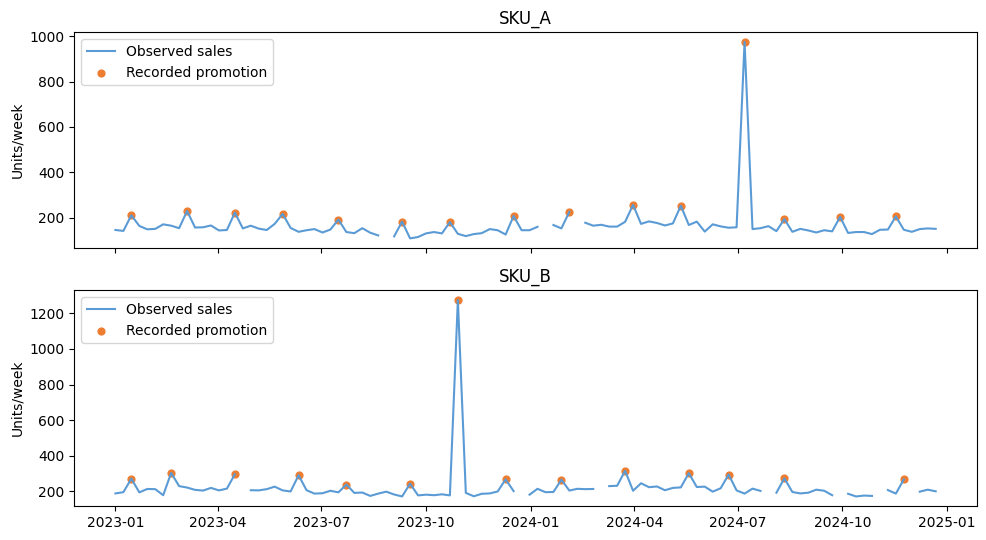

Gaps remain visible. Very high recorded promotion weeks are retained, not assumed erroneous.


In [16]:
raw_data = load_history()
history, audit, quarantined = review_history(raw_data)
display(history[['Week','SKU','Sales_Units','Is_Promo','Price']].head(3))
show_history(history, audit, quarantined)
plot_history(history)

First row: SKU_A recorded 145 sales units in the week labelled 1 January 2023, without a recorded promotion, at recorded price 14.99 in unspecified currency.

## 1. Read the sales history

**BEFORE:** Read how many weekly sales values are known and how many are missing.

**CHANGE:** SHOW_ISSUE_DETAILS: False → True. Reveal unresolved records. Do not alter the data.

**AFTER:** Read the missing or unresolved records. Missing means unknown, not zero.

In [17]:
SHOW_ISSUE_DETAILS = False  # <-- CHANGE HERE: False -> True
show_history(history, audit, quarantined, show_details=SHOW_ISSUE_DETAILS)  # <-- READ OUTPUT

,Count
Raw export rows,206
Exact repeats removed,3
Invalid-date records quarantined,1
Conflicting records quarantined,2
Calendar SKU/weeks,208
Known sales weeks,198
Unknown sales weeks,10


,Calendar_weeks,Known_sales_weeks
SKU,,
SKU_A,104,101
SKU_B,104,97


Unknown sales are not zero. No promotion spikes or prices have been filled or capped.


**THINK — Notice, think, explain**

1. **Notice:** After revealing the record details, how many weekly sales values are still unknown? Did showing the details change the sales history?

2. **Think:** A colleague suggests entering zero for every unknown week before preparing the sales estimate. What would zero tell the forecast that the records do not tell us?

3. **Explain:** Write two sentences to that colleague: what can you report from the history, and what should you ask them to check?

## 2. Review a promotion assumption

**BEFORE:** Read the full-history promotion group means and fixed MA3 reference.

**CHANGE:** UPLIFT_PCT: 0 → 20. Assume a promotion next week and a 20% increase over the fixed reference.

**AFTER:** Compare reference and conditional scenario. Separate observations from the commercial assumption.

In [18]:
UPLIFT_PCT = 0  # <-- CHANGE HERE: 0 -> 20
commercial_plan = promotion_review(history, uplift_pct=UPLIFT_PCT)  # <-- READ OUTPUT

,SKU,Nonpromo weeks,Promo weeks,Nonpromo mean (units/week),Promo mean (units/week),Observed mean gap (%)
0,SKU_A,86,15,148.43,263.07,77.23
1,SKU_B,83,14,201.19,350.86,74.39


,Value
Reference MA3 forecast (units),150.33
Assumed uplift (%),0.00
Conditional commercial scenario (units),150.33


Next week promotion and 20% uplift are teaching assumptions, not dataset facts or fitted effects.
The MA3 reference may already reflect past promotions. Check double counting before an override.
Request promotion type, timing, comparable events and availability. Record owner/reason; evaluate the override later.


**THINK — Notice, think, explain**

1. **Notice:** When the assumed promotion increase changes from 0% to 20%, which SKU_A quantity changes, and which stays the same?

2. **Think:** Sales proposes a promotion next week. Does the higher planning quantity mean we have already observed more sales, or that we are planning for a different situation? Use the two displayed quantities.

3. **Explain:** A colleague asks, “Why is next week’s plan higher than the original forecast?” Give a two-sentence explanation that names the assumption and one detail about the planned promotion to check.

## 3. Compare forecast windows

**BEFORE:** Inspect naïve and MA3 on the validation period, 11 Aug–27 Oct 2024.

**CHANGE:** WINDOW: 3 → 6. Inspect MA6 on exactly the same validation dates. The chart shows all three fixed candidates.

**AFTER:** Read the error comparison and the separate final check below. The helper chooses the method; you interpret what happened.

,SKU,Method,Calendar weeks,Scored weeks,MAE (units/week),Bias (forecast - actual)
0,SKU_A,Naive,12,12,25.08,1.08
1,SKU_A,MA_3,12,12,20.83,3.00
3,SKU_B,Naive,12,2,15.50,15.50
4,SKU_B,MA_3,12,2,15.00,8.33


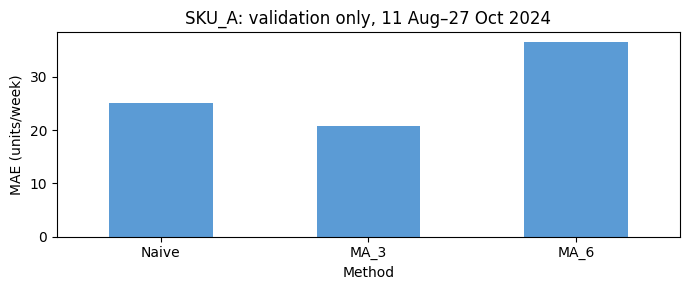

The chart shows all fixed candidates. The table follows your window setting.
Same eligible dates per SKU. Positive bias means overforecasting. No final-period scores appear here.


In [19]:
WINDOW = 3  # <-- CHANGE HERE: 3 -> 6
validation_metrics = show_validation(history, window=WINDOW)  # <-- READ OUTPUT

**Separate final check**
The helper chooses using validation only, then reports final performance. Editing WINDOW changes the inspection table, not that rule. Read this as a check of what we learned, not a reason to choose again.

In [20]:
final_report = show_final_check(history)  # <-- READ: chosen method and benchmark on separate final weeks

,SKU,Method,Calendar weeks,Scored weeks,MAE (units/week),Bias (forecast - actual)
0,SKU_A,Naive,8,8,20.38,-2.88
1,SKU_A,MA_3,8,8,20.42,-4.75


Locked SKU_A choice: MA_3, chosen on validation MAE only. No reselection on final results.
SKU_B final common coverage: 0/8. No automated model recommendation for B.


**THINK — Notice, think, explain**

1. **Notice:** For SKU_A, compare the MA3 and MA6 validation MAE on the same 12 weeks. Which has the smaller average error?

2. **Think:** A colleague says, “Using six weeks instead of three must give a better forecast because it uses more history.” Does this run support that claim? Refer to the two MAE values.

3. **Explain:** On the separate final eight weeks, MA3 has MAE 20.42 and the previous-week forecast has MAE 20.38. What would you tell the colleague about whether MA3 has shown an accuracy improvement?

## 4. Change the planning horizon

**BEFORE:** Read the fixed weekly reference for SKU_A. Start with one future week.

**CHANGE:** HORIZON_WEEKS: 1 → 4. Extend the horizon to four consecutive weeks. Keep the weekly reference unchanged.

**AFTER:** Compare units per week with total units over the selected period.

,Value
Weekly reference (units/week),150.33
Planning horizon (weeks),1.00
Total over the horizon (units),150.33


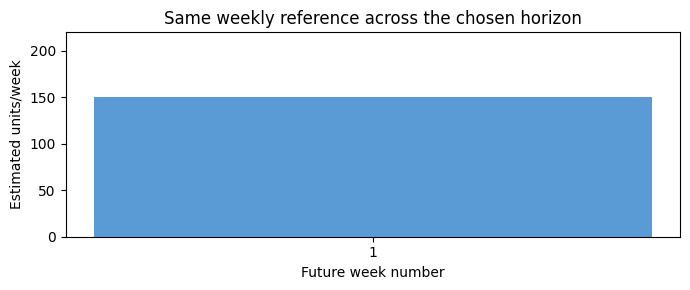

Assumption: the same weekly reference in each future week.
The promotion adjustment is not applied in this task.


In [21]:
HORIZON_WEEKS = 1  # <-- CHANGE HERE: 1 -> 4
horizon_plan = planning_horizon(history, horizon_weeks=HORIZON_WEEKS)  # <-- READ OUTPUT

**THINK — Notice, think, explain**

1. **Notice:** After changing the period from one week to four weeks, compare the weekly estimate and the total. Which changes?

2. **Think:** A colleague sees the four-week total and says, “Sales are now expected to be four times higher each week.” What has the colleague confused?

3. **Explain:** The sales manager asks for an estimate covering the next four weeks. Write a short reply giving the total and the weekly-sales assumption behind it.

## 5. Review a forecast against actual sales

**BEFORE:** Keep the original 150.33 forecast and the assumed+20% forecast 180.40 fixed. Use hypothetical actual sales 150.

**CHANGE:** ACTUAL_UNITS: 150 → 190. Change the hypothetical actual to 190. Do not alter either forecast.

**AFTER:** Compare the two absolute-error bars and the displayed signed errors.

,Version,Forecast (units),Hypothetical actual (units),Signed error (forecast - actual),Absolute error (units)
0,Original forecast,150.33,150,0.33,0.33
1,Assumed +20% adjustment,180.40,150,30.40,30.40


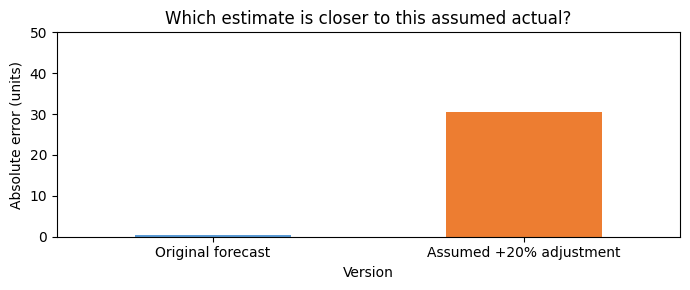

150 and190 are hypothetical actual-sales outcomes, not observations from the source CSV.
Both forecasts are fixed before the outcome. Smaller absolute error means closer for this example only.
One example cannot prove that a promotion adjustment always helps. Review several comparable weeks.


In [22]:
ACTUAL_UNITS = 150  # <-- CHANGE HERE: 150 -> 190
review = review_forecast(history, actual_units=ACTUAL_UNITS)  # <-- READ OUTPUT

**THINK — Notice, think, explain**

1. **Notice:** Compare the two runs with hypothetical actual sales of 150 and 190 units. Which forecast is closer in each run?

2. **Think:** Why does the closer forecast change even though neither forecast was edited? Use the actual sales and the error bars.

3. **Explain:** After the 190-unit example, Sales says, “The promotion adjustment worked, so we should always add 20%.” How would you explain what these two examples show?

## What we learned
Complete these statements: a forecast is…, its quantity must include…, and after actual sales arrive we can…

## Carrying the demand plan forward
Keep the product code, period, estimated units and assumptions together. These are the inputs for the next supply-chain planning question.

Further reading: [Forecasting: Principles and Practice](https://otexts.com/fpp3/toolbox.html).